# 03 — MMR lambda sweep, adaptive controller, and uncertainty

**Goal:** compare a fixed relevance–diversity weight with the proposed query-adaptive controller. This notebook must use validation queries for design. The held-out test set is for the final locked evaluation only.

The controller uses two observable features: a normalized top-score gap as a query-confidence proxy, and average candidate cosine similarity as a shortlist-redundancy proxy. It maps these to a per-query λ. This is deliberately simple so its behavior can be inspected; whether it improves the Pareto frontier is an empirical question.

## 0. Initial Setup

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Image

In [2]:
ROOT = Path.cwd()
if not (ROOT / "src" / "image_rerank").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from image_rerank.experiment import load_cached_split, sweep_mmr_lambdas, evaluate_queries
from image_rerank.statistics import paired_bootstrap_difference
from image_rerank.plots import plot_lambda_sweep, plot_tradeoff
from image_rerank.artifacts import ensure_dir, write_dataframe, write_json

SPLIT = "validation"
ENCODER_KEY = "openclip-ViT-B-32-openai"
MAX_QUERIES = None   # Set None for a full validation analysis.
OUTPUT_DIR = ensure_dir(ROOT / "artifacts" / "experiments" / "adaptive_controller")

queries = load_cached_split(ROOT / "artifacts" / "cache", SPLIT, ENCODER_KEY)
if MAX_QUERIES is not None:
    queries = queries[:MAX_QUERIES]
print("Validation query count:", len(queries))

Validation query count: 40


In [7]:
import seaborn as sns
import matplotlib.pyplot as plt

In [3]:
# Check GPU Access
import torch
print({
    "project_root": str(ROOT),
    "pytorch": torch.__version__,
    "cuda_available": torch.cuda.is_available(),
    "gpu_name": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None,
})

{'project_root': 'd:\\01 Work\\14-research-Image-MMR', 'pytorch': '2.11.0+cu128', 'cuda_available': True, 'gpu_name': 'NVIDIA GeForce RTX 3050 Laptop GPU'}


## 1. Sweep fixed MMR weights

λ=1 is the encoder-similarity ranking (no redundancy penalty). Lower λ places more weight on novelty. The best fixed weight is selected from validation data, not test data.

In [4]:
weights = np.round(np.arange(0.1, 1.01, 0.1), 2)
sweep_df = sweep_mmr_lambdas(queries, lambdas=weights, k=50)
write_dataframe(OUTPUT_DIR / "metrics" / "mmr_lambda_sweep_per_query.csv", sweep_df)

sweep_summary = sweep_df.groupby("lambda_relevance", as_index=False).agg(
    **{
        "ap@50_mean": ("ap@50", "mean"),
        "ap@50_std": ("ap@50", "std"),
        "ild@10_mean": ("ild@10", "mean"),
        "rerank_latency_ms_mean": ("rerank_latency_ms", "mean"),
    }
)
display(sweep_summary.round(4))

,lambda_relevance,ap@50_mean,ap@50_std,ild@10_mean,rerank_latency_ms_mean
0,0.1,0.5603,0.2016,0.2700,0.6332
1,0.2,0.6004,0.1717,0.2277,0.6624
2,0.3,0.6117,0.2120,0.1930,0.6387
3,0.4,0.6129,0.2323,0.1772,0.6373
4,0.5,0.6009,0.2270,0.1632,0.6119
5,0.6,0.5798,0.2153,0.1556,0.6089
6,0.7,0.5666,0.2101,0.1520,0.6294
7,0.8,0.5663,0.2114,0.1487,0.6088
8,0.9,0.5653,0.2119,0.1467,0.6112
9,1.0,0.5650,0.2097,0.1455,0.6088


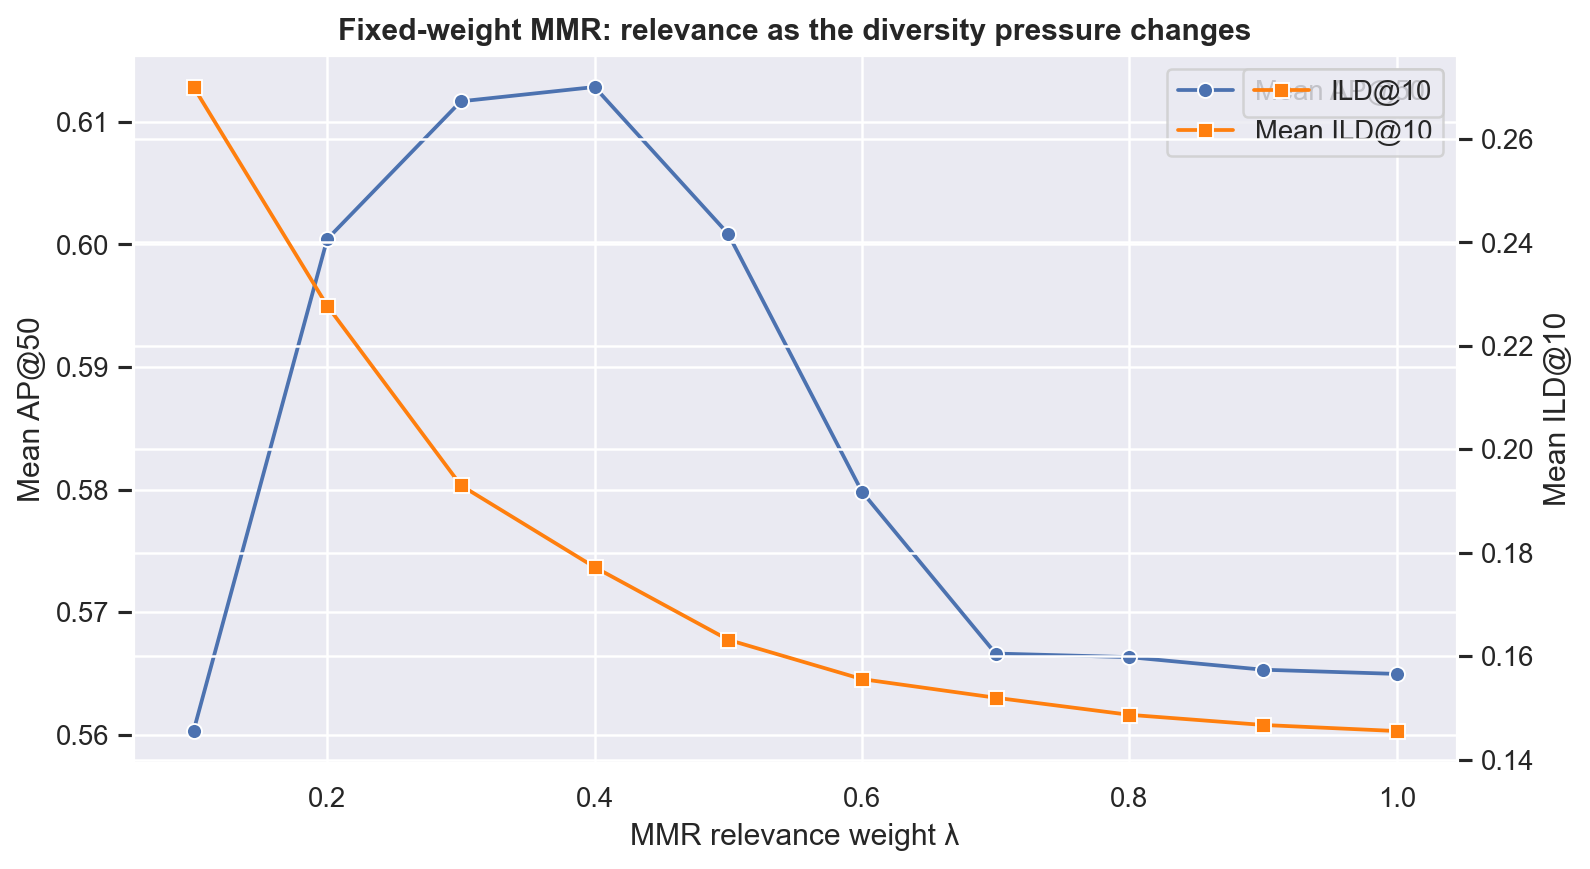

In [5]:
lambda_plot_path = plot_lambda_sweep(
    sweep_df, OUTPUT_DIR / "figures" / "mmr_lambda_sweep.png"
)
display(Image(filename=str(lambda_plot_path)))

## 2. Compare adaptive MMR with the fixed λ=0.70 baseline

The paired bootstrap resamples queries, preserving the fact that each method sees the same shortlist. The confidence interval describes uncertainty in the mean per-query difference. A tiny smoke subset is not suitable for a publication claim; use the full validation split and report the number of queries.

In [6]:
comparison_metrics, comparison_summary = evaluate_queries(
    queries,
    top_k=50,
    diversity_k=10,
    output_dir=OUTPUT_DIR,
    run_name="validation_controller_comparison",
)

ci_ap = paired_bootstrap_difference(
    comparison_metrics,
    metric="ap@50",
    treatment="adaptive_mmr",
    control="mmr_fixed_0.70",
    n_bootstrap=5000,
    seed=42,
)
ci_ild = paired_bootstrap_difference(
    comparison_metrics,
    metric="ild@10",
    treatment="adaptive_mmr",
    control="mmr_fixed_0.70",
    n_bootstrap=5000,
    seed=42,
)
print("AP@50 difference (adaptive - fixed):", ci_ap)
print("ILD@10 difference (adaptive - fixed):", ci_ild)
write_json(OUTPUT_DIR / "metrics" / "adaptive_vs_fixed_bootstrap_ci.json", {
    "ap@50": ci_ap,
    "ild@10": ci_ild,
    "warning": "Smoke subsets provide only a pipeline check; use full validation for inference.",
})
display(comparison_summary.round(4))

AP@50 difference (adaptive - fixed): {'metric': 'ap@50', 'treatment': 'adaptive_mmr', 'control': 'mmr_fixed_0.70', 'n_queries': 40, 'mean_difference': 0.04738056890496326, 'ci_lower': 0.0014887216765712549, 'ci_upper': 0.0986214296659485, 'confidence': 0.95, 'n_bootstrap': 5000}
ILD@10 difference (adaptive - fixed): {'metric': 'ild@10', 'treatment': 'adaptive_mmr', 'control': 'mmr_fixed_0.70', 'n_queries': 40, 'mean_difference': 0.04978495126472353, 'ci_lower': 0.04021978755556903, 'ci_upper': 0.06030758740899904, 'confidence': 0.95, 'n_bootstrap': 5000}


,method,rerank_latency_ms_mean,rerank_latency_ms_std,ap@50_mean,ap@50_std,ndcg@10_mean,ndcg@10_std,recall@10_mean,recall@10_std,ild@10_mean,...,unique_supercategory@10_mean,unique_supercategory@10_std,unique_category@10_mean,unique_category@10_std,unique_iconic_group@10_mean,unique_iconic_group@10_std,unique_inat24_species_name@10_mean,unique_inat24_species_name@10_std,rerank_latency_ms_p50,rerank_latency_ms_p95
0,adaptive_mmr,0.9599,0.1747,0.6140,0.1955,0.2849,0.2460,0.1271,0.1170,0.2017,...,1.0,0.0,1.0,0.0,1.0,0.0,4.100,2.1815,0.9538,1.1967
1,cluster_xquad,29.1973,3.5087,0.5653,0.2097,0.3256,0.2918,0.1471,0.1788,0.1511,...,1.0,0.0,1.0,0.0,1.0,0.0,3.575,2.1470,28.4975,33.3277
2,encoder_similarity,0.0322,0.0258,0.5650,0.2097,0.3313,0.2996,0.1482,0.1789,0.1455,...,1.0,0.0,1.0,0.0,1.0,0.0,3.450,2.1950,0.0254,0.0457
3,greedy_dpp,1.2713,0.2065,0.5832,0.1784,0.2873,0.2429,0.1228,0.1166,0.2051,...,1.0,0.0,1.0,0.0,1.0,0.0,3.950,2.0500,1.2901,1.5156
4,initial_clip,0.0305,0.0057,0.7077,0.1982,0.5140,0.3196,0.2465,0.1911,0.1807,...,1.0,0.0,1.0,0.0,1.0,0.0,3.150,1.8749,0.0295,0.0416
5,mmr_fixed_0.70,0.9472,0.1886,0.5666,0.2101,0.3340,0.2923,0.1514,0.1794,0.1520,...,1.0,0.0,1.0,0.0,1.0,0.0,3.450,2.1237,0.9309,1.2453


## 3. Controller diagnostics

`adaptive_mmr` rows include `lambda_relevance`, `query_confidence`, `candidate_redundancy`, and `top_score_gap_z`. Plotting λ against these diagnostics helps check that the controller behaves as intended rather than behaving like a near-constant weight.

,query_id,query,lambda_relevance,query_confidence,candidate_redundancy,top_score_gap_z,ap@50,ild@10
3,26f08f48fba5,leopard on a road,0.2566,0.0701,0.8548,0.0727,0.5814,0.2935
9,ccfab641388e,an immature bald eagle,0.2629,0.1453,0.8630,0.1570,0.6000,0.1690
15,304b98614020,California Condor tagged with green 26,0.2852,0.2911,0.8141,0.3440,0.7143,0.2650
21,5f843f4b21e0,elephant with radio collar,0.2860,0.4876,0.8865,0.6686,0.5000,0.1695
27,d790a4840da6,A Gila Woodpecker inside its nest in a Saguaro...,0.2653,0.1510,0.8443,0.1637,1.0000,0.2451
33,ef85102b39ad,A tamandua anteater pup clinging to its mother...,0.2817,0.2586,0.8117,0.2992,0.6000,0.2495
39,171718383c53,A male frigatebird with an inflated throat pouch,0.2888,0.3369,0.8228,0.4109,0.8333,0.2442
45,f43f29b7ae6f,birds with wind turbines,0.2639,0.0887,0.7585,0.0929,0.7667,0.2881
51,058104bc38db,A godwit performing distal rhynchokinesis,0.2717,0.2614,0.8721,0.3029,1.0000,0.1885
57,6f213983b615,Black Skimmer performing skimming,0.2701,0.2822,0.8907,0.3316,0.5526,0.1710


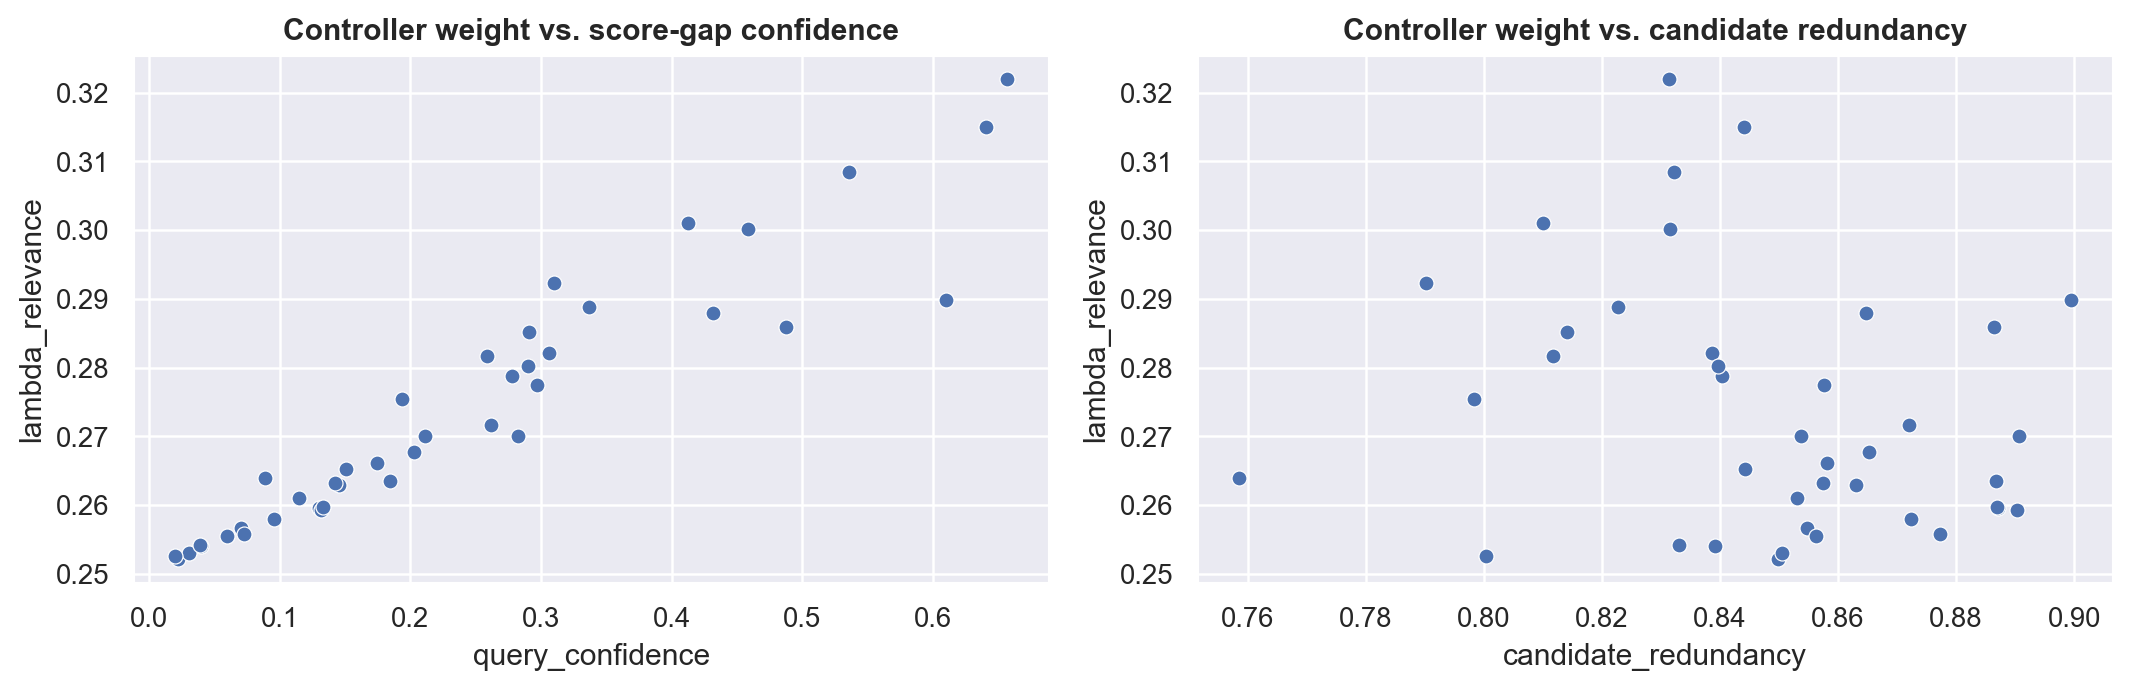

In [8]:
adaptive_rows = comparison_metrics.loc[
    comparison_metrics["method"] == "adaptive_mmr",
    ["query_id", "query", "lambda_relevance", "query_confidence", "candidate_redundancy", "top_score_gap_z", "ap@50", "ild@10"],
]
display(adaptive_rows.round(4))

sns.set_theme(style="darkgrid", context="notebook", palette="deep")
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.scatterplot(data=adaptive_rows, x="query_confidence", y="lambda_relevance", ax=axes[0])
axes[0].set_title("Controller weight vs. score-gap confidence")
sns.scatterplot(data=adaptive_rows, x="candidate_redundancy", y="lambda_relevance", ax=axes[1])
axes[1].set_title("Controller weight vs. candidate redundancy")
fig.tight_layout()
controller_plot = OUTPUT_DIR / "figures" / "controller_diagnostics.png"
fig.savefig(controller_plot, bbox_inches="tight", dpi=180)
plt.close(fig)
display(Image(filename=str(controller_plot)))

## 4. Decision rule for the next iteration

Do not call the adaptive controller better because its ILD is higher. Prefer it only if it improves the validation Pareto frontier under the preregistered relevance-loss and latency limits, with paired uncertainty estimates. If it does not, report the useful finding: a fixed λ or DPP is preferable for this candidate distribution.

# The End